# Лабораторная работа 2. Два класса алгоритмов сортировки

**Опора:** лекции 3–5.

Реализуются **четыре сортировки**:

- пузырьковая — обязательно;
- сортировка подсчётом — обязательно;
- одна из трёх сортировок сравнением: быстрая, слиянием, пирамидальная;
- одна из двух сортировок без сравнений: поразрядная, блочная.

Задача у всех одна: **вход** — список чисел, **выход** — тот же список,
упорядоченный по неубыванию.

Нужно самостоятельно реализовать выбранные алгоритмы, не заменяя их вызовами
готовых сортировок. Конкретный вариант реализации выбирает студент.

In [7]:
import sys
from pathlib import Path

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "labkit").is_dir():
        sys.path.insert(0, str(candidate))
        break

import labkit as lk

print("Режим:", lk.CONFIG.name, "| размеры массивов:", lk.sizes())

Режим: быстрый | размеры массивов: [16, 32, 48, 64, 80, 96, 112, 128, 144, 160, 176, 192, 208, 224, 240, 256, 272, 288, 304, 320, 336, 352, 368, 384, 400, 416, 432, 448, 464, 480, 496, 512]


## Задача 1. Пузырьковая сортировка (обязательно)

Соседние элементы сравниваются и переставляются, пока массив не станет
упорядоченным.

Если полный проход не выполнил ни одного обмена, алгоритм должен завершиться.

In [8]:
def bubble_sort(arr):
    """Пузырьковая сортировка."""
    # TODO: реализовать

    flag = True

    while flag:
        flag = False
        for i in range(1, len(arr)):
            if arr[i] < arr[i - 1]:
                arr[i], arr[i - 1] = arr[i - 1], arr[i]
                flag = True

    return arr

    raise NotImplementedError("bubble_sort")

In [9]:
lk.check_sort(bubble_sort, "Пузырьковая сортировка")
lk.check_early_exit(bubble_sort, "Досрочный выход")

Пузырьковая сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 1

## Задача 2. Сортировка подсчётом (обязательно)

Подсчитывается, сколько раз встречается каждый ключ, после чего элементы
раскладываются по местам.

- **Вход:** неотрицательные целые числа.

In [10]:
def counting_sort(arr):
    """Сортировка подсчётом для неотрицательных целых чисел."""
    # TODO: реализовать

    if len(arr) > 1:
        inclusions = [0] * (max(arr) + 1)
    else: 
        return arr

    for i in arr:
        inclusions[i] += 1
    
    output_arr = []
    for i in range(len(inclusions)):
        output_arr.extend([i] * inclusions[i])

    return output_arr
    
    raise NotImplementedError("counting_sort")

In [11]:
lk.check_sort(counting_sort, "Сортировка подсчётом")

Сортировка подсчётом
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 100

## Выбор 1. Сортировка сравнением

Реализовать **одну** из трёх: быструю, слиянием или пирамидальную.

**Быстрая сортировка.** Разделение по опорному элементу. Способ выбора
опорного элемента определяет студент.

**Сортировка слиянием.** Разделение пополам и слияние упорядоченных частей.

**Пирамидальная сортировка.** Реализацию разделить на три функции:

- `_sift_down(arr, start, size)` восстанавливает свойство max-heap в поддереве;
- `_build_max_heap(arr)` строит max-heap снизу вверх;
- `heap_sort(arr)` сначала строит кучу, затем последовательно извлекает максимум.

In [35]:
def quick_sort(arr):
    """Быстрая сортировка."""
    # TODO: реализовать, если выбрана быстрая сортировка
    raise NotImplementedError("quick_sort")

In [36]:
lk.check_sort(quick_sort, "Быстрая сортировка", optional=True)

Быстрая сортировка: вариант не выбран, тесты пропущены


In [37]:
def merge_sort(arr):
    """Сортировка слиянием."""
    # TODO: реализовать, если выбрана сортировка слиянием
    raise NotImplementedError("merge_sort")

In [38]:
lk.check_sort(merge_sort, "Сортировка слиянием", optional=True)

Сортировка слиянием: вариант не выбран, тесты пропущены


In [12]:
def _sift_down(arr, start, size):
    """Восстановить свойство max-heap в поддереве с корнем start."""
    # TODO: реализовать просеивание вниз

    largest = start
    left = 2 * start + 1
    right = 2 * start + 2

    while True:
        if left >= size:
            break
        if arr[left] > arr[largest]:
            largest = left
        if right < size and arr[right] > arr[largest]:
            largest = right
        if largest != start:
            arr[start], arr[largest] = arr[largest], arr[start]
            start = largest
            left = 2 * start + 1
            right = 2 * start + 2
        else:
            break

    return 0

    raise NotImplementedError("_sift_down")


def _build_max_heap(arr):
    """Построить max-heap снизу вверх."""
    # TODO: реализовать построение кучи

    last_bracnh = (len(arr) // 2) - 1

    for i in range(last_bracnh, -1, -1):
        _sift_down(arr, i, len(arr))
    
    return 0

    raise NotImplementedError("_build_max_heap")


def heap_sort(arr):
    """Пирамидальная сортировка с предварительным построением max-heap."""
    # TODO: построить кучу и последовательно извлечь максимумы

    _build_max_heap(arr)

    for i in range(len(arr) - 1, 0, -1):
        arr[0], arr[i] = arr[i], arr[0] 
        _sift_down(arr, 0, i)
    
    return arr

    raise NotImplementedError("heap_sort")


In [13]:
lk.check_sort(heap_sort, "Пирамидальная сортировка", optional=True)

Пирамидальная сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500,

## Выбор 2. Сортировка без сравнений

Реализовать **одну** из двух.

**Поразрядная сортировка.** Обработка чисел по разрядам. Конкретную схему
выбирает студент; результат должен быть упорядочен по неубыванию.

- **Вход:** неотрицательные целые числа.

In [41]:
def radix_sort(arr):
    """Поразрядная сортировка для неотрицательных целых чисел."""
    # TODO: реализовать, если выбрана поразрядная сортировка
    raise NotImplementedError("radix_sort")

In [42]:
lk.check_sort(radix_sort, "Поразрядная сортировка", optional=True)

Поразрядная сортировка: вариант не выбран, тесты пропущены


**Блочная сортировка.** Значения распределяются по блокам, каждый блок
сортируется отдельно, после чего блоки соединяются по порядку.

- **Вход:** вещественные числа из полуинтервала `[0, 1)`.

In [48]:
import math

def bucket_sort(arr):
    """Блочная сортировка вещественных чисел из [0, 1)."""
    # TODO: реализовать, если выбрана блочная сортировка

    buckets = [[] for _ in range(int(math.sqrt(len(arr))))]
    num_of_buckets = len(buckets)

    for i in arr:
        buckets[min(int(i * num_of_buckets), num_of_buckets - 1)].append(i)
    
    new_arr = []
    for bucket in buckets:
        bubble_sort(bucket)
        new_arr.extend(bucket)

    return new_arr

    raise NotImplementedError("bucket_sort")

In [49]:
lk.check_sort(bucket_sort, "Блочная сортировка", floats=True, optional=True)

Блочная сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [0.5]
    Output: [0.5]
    Expected: [0.5]
  [ok]   два элемента наоборот
    Input: [0.9, 0.1]
    Output: [0.1, 0.9]
    Expected: [0.1, 0.9]
  [ok]   уже отсортирован
    Input: [0.1, 0.2, 0.3]
    Output: [0.1, 0.2, 0.3]
    Expected: [0.1, 0.2, 0.3]
  [ok]   повторяющиеся значения
    Input: [0.3, 0.1, 0.3, 0.1]
    Output: [0.1, 0.1, 0.3, 0.3]
    Expected: [0.1, 0.1, 0.3, 0.3]
  [ok]   значения у краёв
    Input: [0.0, 0.999, 0.001, 0.5]
    Output: [0.0, 0.001, 0.5, 0.999]
    Expected: [0.0, 0.001, 0.5, 0.999]
  [ok]   узкая полоса
    Input: [0.011, 0.01, 0.012, 0.0105]
    Output: [0.01, 0.0105, 0.011, 0.012]
    Expected: [0.01, 0.0105, 0.011, 0.012]
  [ok]   100 случайных массивов
  [ok]   встроенная sorted не используется
  [ok]   метод list.sort не используется
  [ok]   модуль heapq не используется
  Пройдено 11 из 11


## Набор реализованных сортировок

Дальше всё считается по тем реализациям, которые действительно написаны.

In [50]:
INT_SORTS = lk.implemented_sorts({
    "пузырьковая": bubble_sort,
    "подсчётом": counting_sort,
    "быстрая": quick_sort,
    "слиянием": merge_sort,
    "пирамидальная": heap_sort,
    "поразрядная": radix_sort,
})
FLOAT_SORTS = lk.implemented_sorts({"блочная": bucket_sort}, floats=True)

print("В экспериментах участвуют:", ", ".join([*INT_SORTS, *FLOAT_SORTS]))

В экспериментах участвуют: пузырьковая, подсчётом, пирамидальная, блочная


In [51]:
sorting = lk.sorting_table(
    INT_SORTS, FLOAT_SORTS, samples=5, repeats=5,
)

Размер входа: все метрики: 100%|██████████| 640/640 [00:05<00:00, 117.98опыт/s, Размер входа; блочная; Случайный; n=512; вход 5/5]      


## Эксперимент 1. Все сортировки вместе

Случайный вход одного и того же набора значений для всех сортировок.

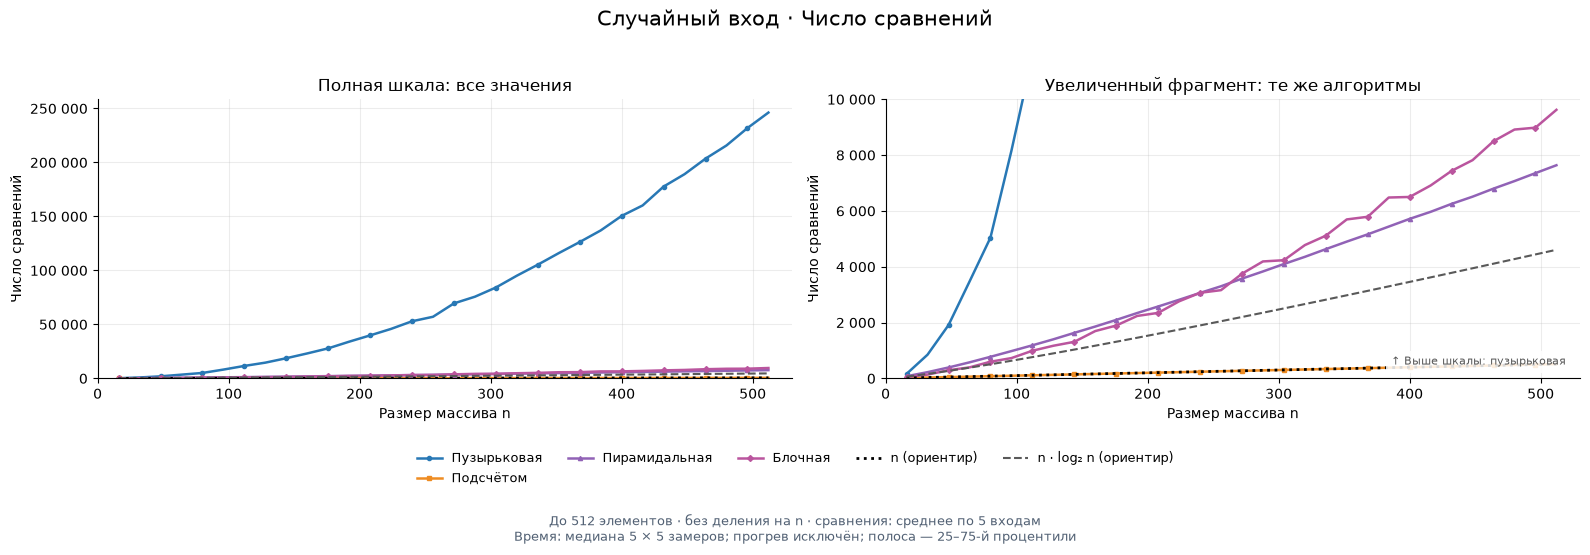

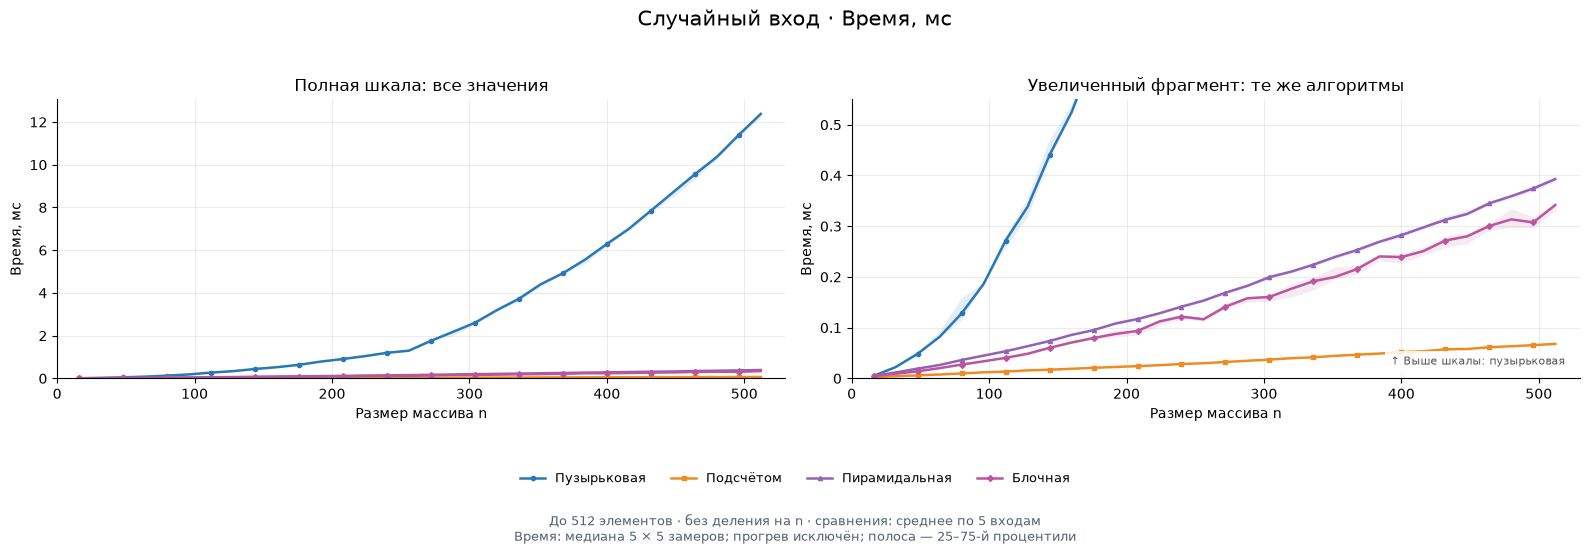

In [52]:
lk.plot_overview(sorting);

## Эксперимент 2. Пространство ключей

Размер массива зафиксирован: `n = 512`. Меняется размер пространства ключей
`k`: элементы случайно выбираются из полуинтервала `[0, k)`. В каждый вход
добавляется ключ `k - 1`, поэтому фактический диапазон не сужается случайно.
Блочная сортировка получает те же ключи, нормированные в диапазон `[0, 1)`.

Результаты разделены по типу алгоритмов:

- для сортировок на сравнениях верхний ряд показывает число сравнений между
  элементами, нижний — время;
- для сортировок, основанных на распределении, верхний ряд показывает число
  выполненных шагов циклов в коде алгоритма и его вспомогательных функций,
  нижний — время.

Один шаг цикла не равен одной машинной операции. Новый счётчик нужен для
сравнения формы зависимостей от `k`, а не абсолютной скорости разных
реализаций.

In [53]:
keyspace = lk.keyspace_table(
    INT_SORTS, FLOAT_SORTS, n=512, samples=5, repeats=5,
)

Пространство ключей: время и работа: 100%|██████████| 260/260 [00:14<00:00, 17.98опыт/s, Пространство ключей; блочная; k = 1048576; k=1048576; вход 5/5]   


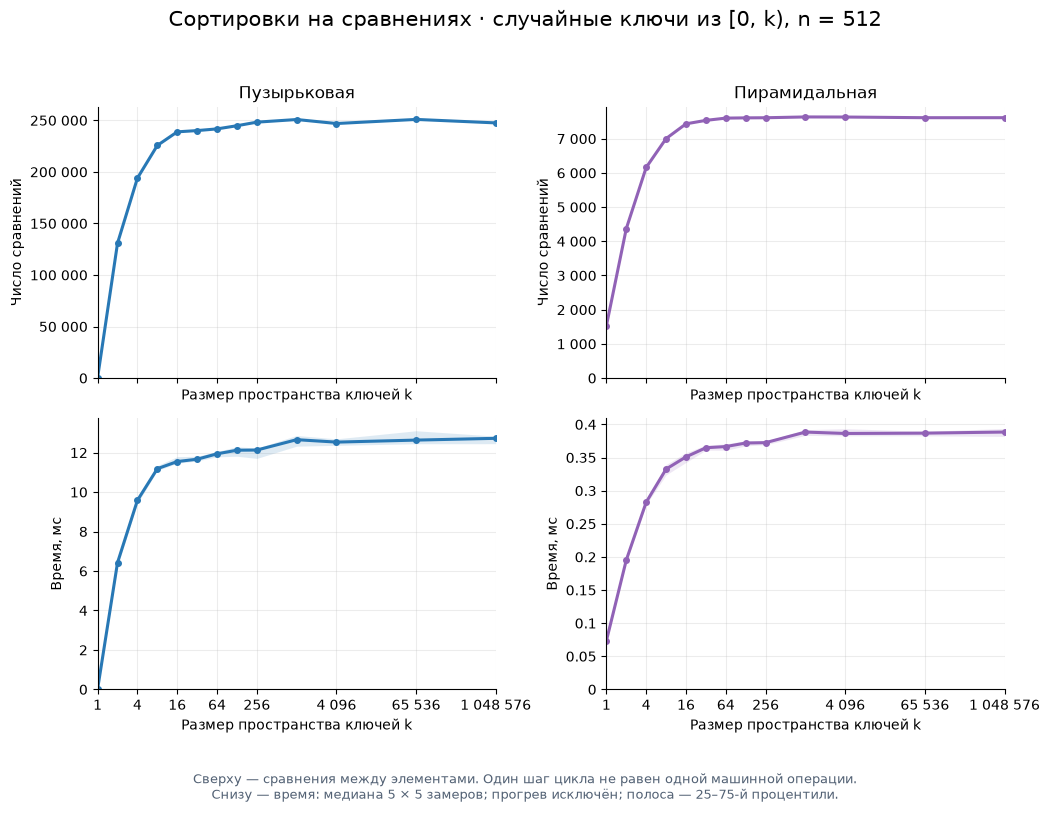

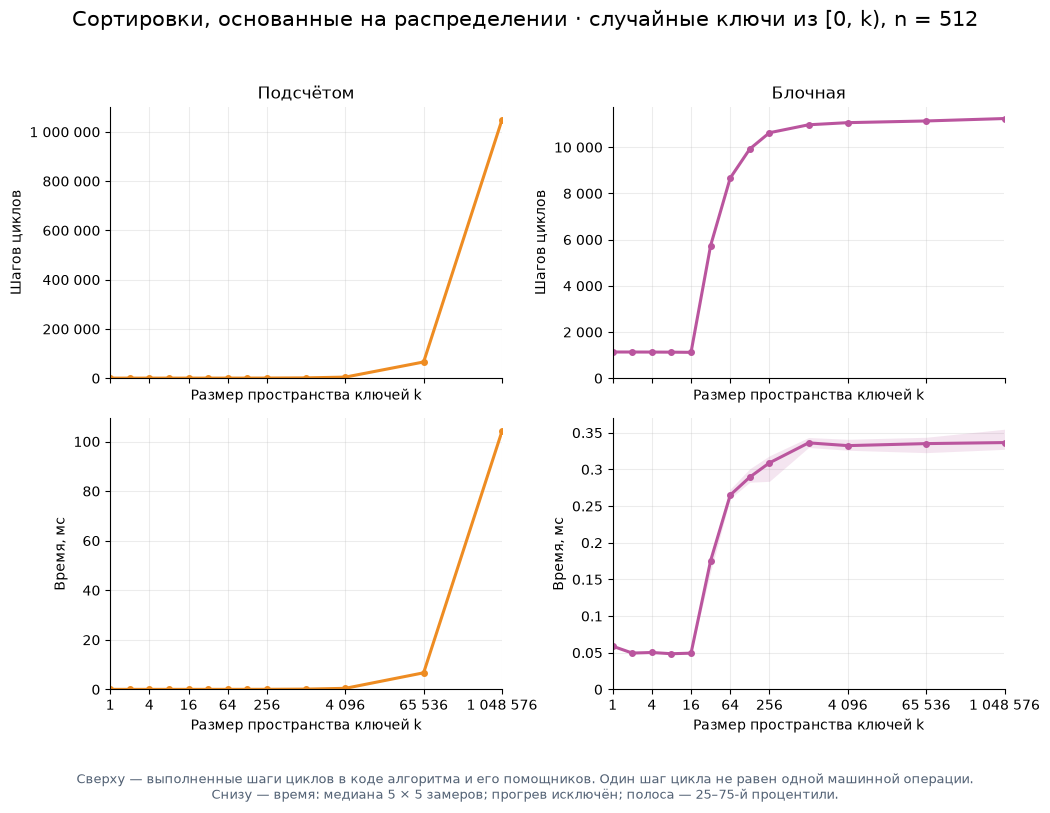

In [54]:
lk.plot_keyspace(keyspace);

## Самостоятельные выводы

Сформулируйте выводы по своим графикам и объясните их устройством реализаций.

1. Почему при увеличении `n` пузырьковая сортировка начинает заметно уступать
   выбранной сортировке сравнением? Какие части алгоритмов определяют форму их
   кривых?
- пузырьковая сортировка начинает уступать пирамидальной, т.к. её сложность O(n^2) по сравнению с O(nlogn). Форма кривых определяется частями алгоритма, зависящими от входных данных: например, если мы просто достаём 1-й элемент, то не важно сколько нам было дано входных данных, время будет константно, если мы проходим 2 раза отдельно по всем элементам, то будет линейно зависить от входных данных, а если мы проходим по данным для каждого элемента (цикл линейно зав. от n вызывающий другой линейный цикл внутри) - то время будет зависеть по форме n^2
2. Почему сортировки подсчётом, поразрядная и блочная могут обходиться без
   `n log n` сравнений? Какие ограничения на входные данные позволяют им это
   делать?
- они могут обходится без nlogn сравнений т.к. не сравнивают эллементы входного массива напрямую. 
Блочная сортировка достигает своей эффективности засчёт ограничения входных данных как [0;1) - если использовать его для сортировки элементов не входящих в этот отрезок, их нужно нормализировать, из-за чего значения теряют точность. Плюс блочная зависит от внешней сортировки самих вёдер и плохо по времени сортирует неравномерно распределённые значения. 
Разрядная сортировка зависит от существования разрядов у сортируемых элементов, что хорошо работает с числами и стрингами, но обычно непременима вне их. Также как и блочная, зависит от внешней сортировки, хотя в её случае, это не настолько плохо из-за малого и предсказуемого числа возможных значений разрядов.
3. Что особенного происходит при `k = 1`, когда все элементы равны? Какие
   алгоритмы могут завершать отдельные этапы раньше, а какие продолжают
   выполнять почти всю предусмотренную работу?
- баблсорт даст свой лучший случай O(n) - он лишь один раз пройдётся по данным.
Подсчёт даст обычный случай, кроме реализаций которые ограничивают набор не только максимумом а и минимумом, тогда можно будет увидеть, что дан набор из одного и того же элемента за меньшее число проходов (в любом случае линейно, но с меньшим коэфициентом)
Пирамидная сортировка увидит что не нужно ничего менять за один проход и даст линейную зависимость
Блочная справится хуже всего, т.к. всё сложит в одно ведро и заставит внешнюю сортировку работать со всем массивом
4. Как повторяющиеся ключи влияют на выбранную сортировку сравнением: на обмены
   пузырьковой сортировки, разбиение быстрой сортировки, слияние или
   восстановление кучи?
- пузырьковая сортировка стабильна, а пирамидная - нет. В обоих случаях повторяющиеся элементы при сравнении требуют меньше действий чем разные.
5. Если выбрана поразрядная сортировка, почему изменение времени связано с
   числом разрядов? Если выбрана блочная — как распределение элементов по
   блокам влияет на стоимость внутренней сортировки?
- для блочной сортировки лучше всего ситуации при которых элементы распределяются по вёдром равномерно, тогда внешней сортировке на вход даётся меньше данных за ведро.
6. Какие различия на графиках следуют из общей идеи алгоритма, а какие могут
   измениться при другом выборе опорного элемента, условии досрочного выхода
   или способе сортировки блоков?
- способ сортировки блоков важен, и может заметно изменить сложность общей сортировки. Из очевидного, если велра богосортить, то разделения по вёдрам не сильно поможет. Также для блочной сортировки важно количество ведёр. Для неизвестного количества входных данных хорошая практика брать квадратный корень количества элементов. Если же известно число входных элементов и оно достаточно мало, лучше всего брать столько вёдер сколько входных элементов.
Также в алгоритмах важно условие досрочного выхода, т.к. проверки до сортировки могут сильно снизить сложность в отдельных случаях в обмен на незначительное ухудщение типичного случая.
Для быстрой сортировки при любом пивоте общий случай - nlogn, но в зависимости от того, что мы знаем о входных данных заранее, можно значительно улучшить реальные случаи выбором пивота.